# Gold Price Forecasting with XGBoost — Daily Model

**Objective.** Test whether a gradient-boosted tree model can forecast the daily Kitco gold price over the same six-month horizon and validation windows as the daily Prophet model in `gold_daily_prophet.ipynb`.

**Design choices**

- **Target:** daily Kitco USD price from the cleaned business-day panel. The model predicts **average daily log return** over a horizon, not the raw price level.
- **Horizon:** 126 business days for the production forecast. Longer horizon ranges are used only to match the 12- and 24-month validation windows.
- **Primary model:** direct multi-horizon XGBoost. Each training row is `(origin, horizon)` with the horizon as a feature and a forward return as the label.
- **Trend bridge:** the target is expressed as average daily return in excess of a capped 252-business-day drift. The cap prevents the tree model from extrapolating an unbounded recent trend. Forecasts are reconstructed from the last observed price.
- **Secondary model:** recursive one-step XGBoost, included as a diagnostic for error accumulation.
- **Feature sets:** a core macro set, an origin-only ablation, a market-risk extension, and separate Brent/WTI oil ablations.
- **Validation:** identical 24-month holdout and four expanding 12-month walk-forward cutoffs as the Prophet notebook. Hyperparameters are not selected on the outer holdout.
- **Intervals:** XGBoost quantile models at 2.5%, 50%, and 97.5% are evaluated as a diagnostic. The published band is a lognormal 95% interval scaled by 63-day realised gold volatility, because the quantile models under-covered the holdout.
- **Outputs:** `model_building/output_daily_xgb/`.

## Step 0 — Setup

The notebook resolves the repository root whether it is launched from the repository root or from `model_building/`.

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost
from xgboost import XGBRegressor
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)

ROOT = Path.cwd()
if not (ROOT / "data-sources").exists():
    ROOT = ROOT.parent

DATA = ROOT / "data-sources"
MODEL_DIR = ROOT / "model_building"
IN = MODEL_DIR / "output_daily"
OUT = MODEL_DIR / "output_daily_xgb"
OUT.mkdir(parents=True, exist_ok=True)

HORIZON = 126
HOLDOUT_MONTHS = 24
WF_CUTS = [
    pd.Timestamp("2022-10-26"),
    pd.Timestamp("2023-10-26"),
    pd.Timestamp("2024-10-26"),
    pd.Timestamp("2025-10-26"),
]
DRIFT_CAP = 0.0008
INNER_CUTS = [
    pd.Timestamp("2021-10-26"),
    pd.Timestamp("2022-10-26"),
    pd.Timestamp("2023-10-26"),
]

print(f"Repository: {ROOT}")
print(f"pandas {pd.__version__} | xgboost {xgboost.__version__}")
print(f"Input directory: {IN}")
print(f"Output directory: {OUT}")

Repository: /home/kosala/git-repos/gold_prediction
pandas 3.1.0 | xgboost 3.4.1
Input directory: /home/kosala/git-repos/gold_prediction/model_building/output_daily
Output directory: /home/kosala/git-repos/gold_prediction/model_building/output_daily_xgb


## Step 1 — Load the cleaned daily panel

The XGBoost notebook reuses the target and release-lag-aligned external panel produced by the Prophet notebook. This keeps the comparison apples-to-apples and avoids duplicating the data-cleaning logic. The original target remains unchanged: missing business days are not interpolated for training, although gold is forward-filled only when constructing technical features.

In [2]:
panel = pd.read_csv(IN / "feature_panel_daily.csv", parse_dates=["ds"]).set_index("ds").sort_index()
future_regs = pd.read_csv(IN / "future_regressors_daily.csv", parse_dates=["ds"]).set_index("ds").sort_index()
target = panel["gold"].copy()
bdays = panel.index
obs = target.notna()

assert bdays.equals(pd.bdate_range(bdays.min(), bdays.max()))
assert future_regs.index.equals(pd.bdate_range(bdays.max() + pd.Timedelta(days=1), periods=HORIZON))

last_observed = target.dropna().index.max()
last_price = float(target.loc[last_observed])
missing_days = int((~obs).sum())

print(f"Panel: {panel.shape[0]:,} business days, {panel.shape[1]:,} columns")
print(f"Target: {target.notna().sum():,} observations, {missing_days} missing business days")
print(f"Range: {bdays.min().date()} -> {bdays.max().date()}")
print(f"Last observation: {last_observed.date()} = ${last_price:,.2f}")
print(f"Future exogenous rows: {len(future_regs)}")
display(future_regs.head(3))
display(future_regs.tail(3))

Panel: 3,058 business days, 99 columns
Target: 2,652 observations, 406 missing business days
Range: 2015-02-05 -> 2026-10-26
Last observation: 2026-10-26 = $4,015.80
Future exogenous rows: 126


,ust10y,dxy,fed_funds,cpi_yoy
ds,,,,
2026-10-27,4.987343,101.45,3.75,4.02331
2026-10-28,4.988700,101.45,3.75,4.02331
2026-10-29,4.990056,101.45,3.75,4.02331


,ust10y,dxy,fed_funds,cpi_yoy
ds,,,,
2027-04-16,4.945541,103.678934,3.833165,4.122819
2027-04-19,4.957885,103.678934,3.833165,4.122819
2027-04-20,4.962167,103.678934,3.833165,4.122819


## Step 2 — Leakage-safe feature engineering

Every feature at forecast origin `t` is known by the end of `t`. External market and macro features are shifted by one business day before use. Gold technical features are computed from the forward-filled observed gold series because the raw target has 406 missing weekdays; the training label is still taken only from observed target dates.

The feature groups are:

- **Gold technicals:** multi-horizon returns, realized volatility, moving-average distances, RSI, MACD, Bollinger z-score, drawdown, skew, kurtosis, and days since the last observation.
- **Macro:** US 10-year yield, DXY, Fed funds, CPI YoY, and real yield, with levels, changes over 1/5/21/63 business days, and 252-day z-scores.
- **Market risk:** S&P 500 and GPR features, plus cross-asset relative momentum.
- **Oil:** Brent and WTI are separate ablations; never both in the same model because they are almost perfectly collinear. WTI uses differences because its 2020 settlement was negative.
- **Calendar:** origin and target-date day-of-week, month sine/cosine, month-end, and quarter-end flags.
- **Known future macro:** target-date core macro levels and their change from the origin. The production forecast uses `future_regressors_daily.csv`; historical validation uses realised values as a known-future-covariate assumption.

In [3]:
CORE = ["ust10y", "dxy", "fed_funds", "cpi_yoy"]
MARKET = ["sp500", "gpr_ma7"]
EXT_COLS = CORE + ["real_yield"] + MARKET + ["brent", "wti"]


def rsi(series, window=14):
    delta = series.diff()
    gain = delta.clip(lower=0).ewm(alpha=1 / window, adjust=False).mean()
    loss = (-delta.clip(upper=0)).ewm(alpha=1 / window, adjust=False).mean()
    rs = gain / loss.replace(0, np.nan)
    return 100 - 100 / (1 + rs)


def target_calendar(dates):
    dates = pd.DatetimeIndex(dates)
    frame = pd.DataFrame(index=dates)
    frame["t_dow"] = dates.dayofweek.astype(float)
    frame["t_month_sin"] = np.sin(2 * np.pi * (dates.month - 1) / 12)
    frame["t_month_cos"] = np.cos(2 * np.pi * (dates.month - 1) / 12)
    frame["t_is_month_end"] = dates.is_month_end.astype(float)
    frame["t_is_quarter_end"] = dates.is_quarter_end.astype(float)
    return frame


def origin_calendar(dates):
    dates = pd.DatetimeIndex(dates)
    frame = pd.DataFrame(index=dates)
    frame["dow"] = dates.dayofweek.astype(float)
    frame["month_sin"] = np.sin(2 * np.pi * (dates.month - 1) / 12)
    frame["month_cos"] = np.cos(2 * np.pi * (dates.month - 1) / 12)
    frame["is_month_end"] = dates.is_month_end.astype(float)
    frame["is_quarter_end"] = dates.is_quarter_end.astype(float)
    return frame


def build_features(gold_series, external):
    gold = gold_series.astype(float)
    gold_ff = gold.ffill()
    log_gold = np.log(gold_ff.where(gold_ff > 0))
    frame = pd.DataFrame(index=gold.index)

    for n in (1, 5, 10, 21, 63, 126, 252):
        frame[f"gold_ret_{n}"] = log_gold.diff(n)
    for n in (5, 21, 63):
        frame[f"gold_vol_{n}"] = frame["gold_ret_1"].rolling(n).std()
    for n in (10, 20, 50, 200):
        frame[f"gold_ma_dist_{n}"] = log_gold - np.log(gold_ff.rolling(n).mean())

    frame["gold_rsi_14"] = rsi(gold_ff, 14)
    ema12 = gold_ff.ewm(span=12, adjust=False).mean()
    ema26 = gold_ff.ewm(span=26, adjust=False).mean()
    macd = ema12 - ema26
    signal = macd.ewm(span=9, adjust=False).mean()
    frame["gold_macd_over_px"] = macd / gold_ff
    frame["gold_macd_hist_over_px"] = (macd - signal) / gold_ff

    ma20 = gold_ff.rolling(20).mean()
    sd20 = gold_ff.rolling(20).std()
    frame["gold_bollinger_z_20"] = (gold_ff - ma20) / sd20.replace(0, np.nan)
    frame["gold_drawdown_252"] = log_gold - np.log(gold_ff.rolling(252).max())
    frame["gold_skew_63"] = frame["gold_ret_1"].rolling(63).skew()
    frame["gold_kurt_63"] = frame["gold_ret_1"].rolling(63).kurt()
    frame["gold_ret_z_20"] = frame["gold_ret_1"] / frame["gold_vol_21"].replace(0, np.nan)

    positions = pd.Series(np.arange(len(gold)), index=gold.index)
    last_obs_pos = positions.where(gold.notna()).ffill()
    frame["days_since_obs"] = (positions - last_obs_pos).fillna(999).astype(float)

    ext = external.reindex(gold.index)
    ext_lag = ext.shift(1)

    for column in ["ust10y", "dxy", "fed_funds", "cpi_yoy", "real_yield"]:
        frame[f"{column}_level"] = ext_lag[column]
        for n in (1, 5, 21, 63):
            frame[f"{column}_chg_{n}"] = ext_lag[column].diff(n)
        frame[f"{column}_z252"] = (
            (ext_lag[column] - ext_lag[column].rolling(252).mean())
            / ext_lag[column].rolling(252).std().replace(0, np.nan)
        )

    sp500_log = np.log(ext_lag["sp500"].where(ext_lag["sp500"] > 0))
    for n in (1, 5, 21, 63):
        frame[f"sp500_ret_{n}"] = sp500_log.diff(n)
    frame["sp500_vol_21"] = sp500_log.diff(1).rolling(21).std()
    frame["sp500_z252"] = (
        (ext_lag["sp500"] - ext_lag["sp500"].rolling(252).mean())
        / ext_lag["sp500"].rolling(252).std().replace(0, np.nan)
    )

    frame["gpr_ma7_level"] = ext_lag["gpr_ma7"]
    for n in (1, 5, 21, 63):
        frame[f"gpr_ma7_chg_{n}"] = ext_lag["gpr_ma7"].diff(n)
    frame["gpr_ma7_z252"] = (
        (ext_lag["gpr_ma7"] - ext_lag["gpr_ma7"].rolling(252).mean())
        / ext_lag["gpr_ma7"].rolling(252).std().replace(0, np.nan)
    )

    brent_log = np.log(ext_lag["brent"].where(ext_lag["brent"] > 0))
    for n in (1, 5, 21, 63):
        frame[f"brent_ret_{n}"] = brent_log.diff(n)
    frame["brent_vol_21"] = brent_log.diff(1).rolling(21).std()

    for n in (1, 5, 21, 63):
        frame[f"wti_chg_{n}"] = ext_lag["wti"].diff(n)
    frame["wti_vol_21"] = ext_lag["wti"].diff(1).rolling(21).std()

    frame["gold_minus_dxy_21"] = frame["gold_ret_21"] - frame["dxy_chg_21"]
    frame["gold_minus_sp500_21"] = frame["gold_ret_21"] - frame["sp500_ret_21"]
    frame["gold_minus_real_yield_21"] = frame["gold_ret_21"] - frame["real_yield_chg_21"]
    return frame

In [4]:
all_dates = bdays.union(future_regs.index)
ext_all = panel[EXT_COLS].reindex(all_dates).ffill()
for column in CORE:
    ext_all.loc[future_regs.index, column] = future_regs[column].to_numpy()
ext_all["real_yield"] = ext_all["ust10y"] - ext_all["cpi_yoy"]
ext_ff_hist = ext_all.reindex(bdays).ffill()

F_hist = build_features(target, ext_all).loc[bdays].join(origin_calendar(bdays))

GOLD_FEATURES = [
    column for column in F_hist.columns
    if column.startswith("gold_") and not column.startswith("gold_minus")
] + ["days_since_obs"]
CORE_ORIGIN = GOLD_FEATURES + [
    column for column in F_hist.columns
    if column.startswith(("ust10y_", "dxy_", "fed_funds_", "cpi_yoy_", "real_yield_"))
] + ["gold_minus_dxy_21", "gold_minus_real_yield_21"] + list(origin_calendar(bdays).columns)
MARKET_ORIGIN = [
    column for column in F_hist.columns if column.startswith(("sp500_", "gpr_"))
] + ["gold_minus_sp500_21"]
BRENT_ORIGIN = [column for column in F_hist.columns if column.startswith("brent_")]
WTI_ORIGIN = [column for column in F_hist.columns if column.startswith("wti_")]

FUTURE_CORE = [
    f"fut_{column}" for column in ["ust10y", "dxy", "fed_funds", "cpi_yoy", "real_yield"]
] + [
    f"fut_{column}_chg" for column in ["ust10y", "dxy", "fed_funds", "cpi_yoy", "real_yield"]
]
TARGET_CAL = ["t_dow", "t_month_sin", "t_month_cos", "t_is_month_end", "t_is_quarter_end"]

BASE = list(dict.fromkeys(CORE_ORIGIN + TARGET_CAL))
FSETS = {
    "Core origin": BASE,
    "Core + future macro": list(dict.fromkeys(BASE + FUTURE_CORE)),
    "Core + future macro + market": list(dict.fromkeys(BASE + FUTURE_CORE + MARKET_ORIGIN)),
    "Core + future macro + Brent": list(dict.fromkeys(BASE + FUTURE_CORE + BRENT_ORIGIN)),
    "Core + future macro + WTI": list(dict.fromkeys(BASE + FUTURE_CORE + WTI_ORIGIN)),
}

print("Feature-set sizes:")
for name, features in FSETS.items():
    print(f"  {name}: {len(features)}")

static_names = [c for c in FSETS["Core + future macro"] if c not in FUTURE_CORE and c not in TARGET_CAL]
missing = F_hist[static_names].isna().mean().sort_values(ascending=False).head(8)
print("\nLargest missing shares in the core + future set:")
print(missing.round(4).to_string())

Feature-set sizes:
  Core origin: 65
  Core + future macro: 75
  Core + future macro + market: 88
  Core + future macro + Brent: 80
  Core + future macro + WTI: 80

Largest missing shares in the core + future set:
fed_funds_z252       0.0925
gold_ret_252         0.0824
ust10y_z252          0.0824
dxy_z252             0.0824
cpi_yoy_z252         0.0824
real_yield_z252      0.0824
gold_drawdown_252    0.0821
gold_ma_dist_200     0.0651


## Step 3 — Return target and capped trend bridge

A raw-price XGBoost target would force trees to extrapolate a level they have never seen. The model therefore learns the **average daily log return** over horizon `h`:

`y_h = log(P[t+h] / P[t]) / h`

A 252-day trailing drift is subtracted from the label and added back when reconstructing prices. The drift is capped at `0.0008` log points per day, roughly 20% annualised, so a recent bull or bear run cannot create an unbounded six-month projection.

`P_hat[t+h] = P[t] * exp((y_hat_h + drift_cap[t]) * h)`

This is not target leakage: the drift uses only the trailing 252 observed business days at origin `t`.

In [5]:
raw_drift = (F_hist["gold_ret_252"] / 252.0).fillna(0.0)
DRIFT = raw_drift.clip(-DRIFT_CAP, DRIFT_CAP)

DYN_HIST = target_calendar(bdays)
for column in ["ust10y", "dxy", "fed_funds", "cpi_yoy", "real_yield"]:
    DYN_HIST[f"fut_{column}"] = ext_ff_hist[column].to_numpy(dtype=float)
    DYN_HIST[f"fut_{column}_chg"] = (
        ext_ff_hist[column].to_numpy(dtype=float)
        - ext_ff_hist[column].shift(1).to_numpy(dtype=float)
    )
DYN_HIST = DYN_HIST.astype(np.float32)

DYN_FUT = target_calendar(future_regs.index)
origin_known = ext_ff_hist.shift(1).loc[last_observed]
for column in ["ust10y", "dxy", "fed_funds", "cpi_yoy", "real_yield"]:
    if column == "real_yield":
        future_value = (
            future_regs["ust10y"].to_numpy(dtype=float)
            - future_regs["cpi_yoy"].to_numpy(dtype=float)
        )
    else:
        future_value = future_regs[column].to_numpy(dtype=float)
    DYN_FUT[f"fut_{column}"] = future_value
    DYN_FUT[f"fut_{column}_chg"] = future_value - float(origin_known[column])
DYN_FUT = DYN_FUT.astype(np.float32)


def build_direct_dataset(feature_names, hmax, cutoff=None, stride=3):
    origins = np.where(obs.to_numpy())[0]
    if cutoff is not None:
        origins = origins[bdays[origins] < cutoff]
    if stride > 1 and len(origins) > 0:
        selected = origins[::stride]
        if selected[-1] != origins[-1]:
            selected = np.append(selected, origins[-1])
        origins = selected

    dynamic = [c for c in feature_names if c in FUTURE_CORE or c in TARGET_CAL]
    static = [c for c in feature_names if c not in dynamic]
    X0 = F_hist[static].to_numpy(dtype=np.float32)
    D0 = DYN_HIST[dynamic].to_numpy(dtype=np.float32)
    gold = target.to_numpy(dtype=float)
    drift = DRIFT.to_numpy(dtype=float)

    rows = []
    for h in range(1, hmax + 1):
        target_positions = origins + h
        valid = target_positions < len(bdays)
        safe_positions = np.clip(target_positions, 0, len(bdays) - 1)
        if cutoff is not None:
            valid &= bdays[safe_positions] < cutoff
        valid &= np.isfinite(gold[safe_positions]) & np.isfinite(gold[origins])
        if not valid.any():
            continue

        origin_pos = origins[valid]
        target_pos = target_positions[valid]
        horizon_col = np.full((len(origin_pos), 1), h, dtype=np.float32)
        X = np.column_stack([horizon_col, X0[origin_pos], D0[target_pos]])
        frame = pd.DataFrame(X, columns=["horizon"] + static + dynamic)
        frame["origin_ds"] = bdays[origin_pos]
        frame["target_ds"] = bdays[target_pos]
        frame["h"] = h
        frame["y"] = np.log(gold[target_pos] / gold[origin_pos]) / h - drift[origin_pos]
        rows.append(frame)

    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

## Step 4 — Prediction and evaluation helpers

The same model object can produce a holdout path, a walk-forward path, or the final 126-day path by changing only the origin and target dates.

In [6]:
BASE_PARAMS = dict(
    n_estimators=400,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=20,
    reg_lambda=10.0,
    reg_alpha=1.0,
    base_score=0.0,
    tree_method="hist",
    n_jobs=4,
    random_state=42,
    verbosity=0,
    objective="reg:squarederror",
)


def split_feature_names(feature_names):
    dynamic = [c for c in feature_names if c in FUTURE_CORE or c in TARGET_CAL]
    static = [c for c in feature_names if c not in dynamic]
    return static, dynamic


def error_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    error = predicted - actual
    return {
        "MAPE": float(np.mean(np.abs(error / actual)) * 100),
        "RMSE": float(np.sqrt(np.mean(error ** 2))),
        "MAE": float(np.mean(np.abs(error))),
    }


def predict_direct(model, feature_names, origin_date, target_dates, future=False, iteration_range=None):
    static, dynamic = split_feature_names(feature_names)
    origin_date = pd.Timestamp(origin_date)
    target_dates = pd.DatetimeIndex(target_dates)
    origin_pos = bdays.get_loc(origin_date)

    if future:
        h = np.arange(1, len(target_dates) + 1)
        D = DYN_FUT.loc[target_dates]
    else:
        target_pos = bdays.get_indexer(target_dates)
        if (target_pos < 0).any():
            raise ValueError("Target dates not present in the business-day index")
        h = target_pos - origin_pos
        D = DYN_HIST.loc[target_dates]

    X_static = np.repeat(
        F_hist.loc[[origin_date], static].to_numpy(dtype=np.float32),
        len(target_dates),
        axis=0,
    )
    X = np.column_stack([h.astype(np.float32)[:, None], X_static, D[dynamic].to_numpy(dtype=np.float32)])
    kwargs = {"iteration_range": iteration_range} if iteration_range is not None else {}
    prediction = model.predict(X, **kwargs)

    origin_price = float(target.loc[origin_date])
    drift = float(DRIFT.loc[origin_date])
    return pd.DataFrame({
        "ds": target_dates,
        "pred_logret": prediction + drift,
        "pred": origin_price * np.exp((prediction + drift) * h),
        "h": h,
    })


def fit_direct_model(feature_names, cutoff, hmax, params, stride=3):
    train = build_direct_dataset(feature_names, hmax=hmax, cutoff=cutoff, stride=stride)
    static, dynamic = split_feature_names(feature_names)
    columns = ["horizon"] + static + dynamic
    model = XGBRegressor(**params)
    model.fit(train[columns], train["y"])
    return model, train, columns


def eval_direct(feature_names, cutoff, months, hmax, params, stride=3):
    model, train, columns = fit_direct_model(feature_names, cutoff, hmax, params, stride)
    origin_date = target.loc[target.index < cutoff].dropna().index.max()
    end_date = cutoff + pd.DateOffset(months=months)
    test = target[(target.index >= cutoff) & (target.index < end_date)].dropna()
    predicted = predict_direct(model, feature_names, origin_date, test.index)
    test_frame = pd.DataFrame({"ds": test.index, "actual": test.values}).merge(predicted, on="ds", how="left")
    metrics = error_metrics(test_frame["actual"], test_frame["pred"])
    return {
        "metrics": metrics,
        "test": test_frame,
        "model": model,
        "train": train,
        "columns": columns,
        "origin_date": origin_date,
        "train_n": len(train),
        "test_n": len(test_frame),
    }


def eval_random_walk(cutoff, months):
    origin_date = target.loc[target.index < cutoff].dropna().index.max()
    end_date = cutoff + pd.DateOffset(months=months)
    test = target[(target.index >= cutoff) & (target.index < end_date)].dropna()
    predicted = np.full(len(test), float(target.loc[origin_date]))
    return error_metrics(test.to_numpy(), predicted)

## Step 5 — Prophet and random-walk baselines

Prophet metrics are read from the already executed daily notebook rather than recomputed. The random walk is the same last-observed-price benchmark used in the Prophet discussion.

In [7]:
prophet_holdout = pd.read_csv(IN / "model_comparison_daily.csv")
prophet_holdout_row = prophet_holdout.loc[prophet_holdout["model"] == "Selected 4-regressor"].iloc[0]
prophet_wf = pd.read_csv(IN / "walk_forward_metrics_daily.csv")
prophet_wf_mean = prophet_wf[["MAPE_anchored", "RMSE_anchored", "MAE_anchored"]].mean()

rw_holdout = eval_random_walk(pd.Timestamp("2024-10-26"), 24)
rw_wf_rows = [eval_random_walk(cutoff, 12) for cutoff in WF_CUTS]
rw_wf_mean = pd.DataFrame(rw_wf_rows)[["MAPE", "RMSE", "MAE"]].mean()

baseline_rows = [
    {"model": "Prophet selected 4-regressor", "evaluation": "24m holdout",
     "MAPE": prophet_holdout_row["MAPE_anchored"], "RMSE": prophet_holdout_row["RMSE_anchored"],
     "MAE": prophet_holdout_row["MAE_anchored"]},
    {"model": "Prophet selected 4-regressor", "evaluation": "12m walk-forward mean",
     "MAPE": prophet_wf_mean["MAPE_anchored"], "RMSE": prophet_wf_mean["RMSE_anchored"],
     "MAE": prophet_wf_mean["MAE_anchored"]},
    {"model": "Random walk", "evaluation": "24m holdout", **rw_holdout},
    {"model": "Random walk", "evaluation": "12m walk-forward mean", **rw_wf_mean.to_dict()},
]
baseline_table = pd.DataFrame(baseline_rows)
display(baseline_table)

,model,evaluation,MAPE,RMSE,MAE
0,Prophet selected 4-regressor,24m holdout,6.351629,420.087722,276.838774
1,Prophet selected 4-regressor,12m walk-forward mean,5.990417,242.700167,197.490863
2,Random walk,24m holdout,26.047770,1314.371389,1098.396047
3,Random walk,12m walk-forward mean,11.451526,424.658757,340.305027


## Step 6 — Feature-set comparison

The comparison is deliberately run on the four walk-forward folds first; the 24-month holdout is reported alongside it but is not used to choose the feature set. Oil is tested only as a separate ablation.

In [8]:
fs_rows = []
for feature_set_name, features in FSETS.items():
    t0 = time.time()
    holdout_result = eval_direct(features, pd.Timestamp("2024-10-26"), 24, 530, BASE_PARAMS, stride=3)
    wf_results = []
    for cutoff in WF_CUTS:
        wf_results.append(eval_direct(features, cutoff, 12, 270, BASE_PARAMS, stride=3)["metrics"])
    wf_frame = pd.DataFrame(wf_results)
    fs_rows.append({
        "feature_set": feature_set_name,
        "n_features": len(features),
        "holdout_MAPE": holdout_result["metrics"]["MAPE"],
        "holdout_RMSE": holdout_result["metrics"]["RMSE"],
        "holdout_MAE": holdout_result["metrics"]["MAE"],
        "wf_MAPE": wf_frame["MAPE"].mean(),
        "wf_RMSE": wf_frame["RMSE"].mean(),
        "wf_MAE": wf_frame["MAE"].mean(),
        "fit_seconds": time.time() - t0,
    })
    print(f"{feature_set_name}: holdout MAPE {fs_rows[-1]['holdout_MAPE']:.3f}% | wf MAPE {fs_rows[-1]['wf_MAPE']:.3f}%", flush=True)

feature_set_table = pd.DataFrame(fs_rows).sort_values(["wf_MAPE", "holdout_MAPE"]).reset_index(drop=True)
display(feature_set_table)
feature_set_table.to_csv(OUT / "xgb_feature_set_comparison.csv", index=False)
SELECTED_SET = feature_set_table.iloc[0]["feature_set"]
SELECTED_FEATURES = FSETS[SELECTED_SET]
print(f"Selected feature set by walk-forward MAPE: {SELECTED_SET} ({len(SELECTED_FEATURES)} features)")

Core origin: holdout MAPE 8.267% | wf MAPE 11.517%


Core + future macro: holdout MAPE 7.398% | wf MAPE 11.198%


Core + future macro + market: holdout MAPE 8.048% | wf MAPE 11.535%


Core + future macro + Brent: holdout MAPE 7.684% | wf MAPE 11.362%


Core + future macro + WTI: holdout MAPE 7.527% | wf MAPE 11.549%


,feature_set,n_features,holdout_MAPE,holdout_RMSE,holdout_MAE,wf_MAPE,wf_RMSE,wf_MAE,fit_seconds
0,Core + future macro,75,7.398349,453.786464,314.737758,11.197884,409.370169,328.055921,80.889084
1,Core + future macro + Brent,80,7.684377,477.849698,327.732990,11.361928,404.760970,326.591853,85.122647
2,Core origin,65,8.267031,475.767745,348.107913,11.516761,427.152082,342.593241,62.221714
3,Core + future macro + market,88,8.047523,491.981645,343.513482,11.534966,418.390311,336.513418,95.913247
4,Core + future macro + WTI,80,7.527279,464.672690,320.616082,11.548704,413.577362,333.639896,85.382369


Selected feature set by walk-forward MAPE: Core + future macro (75 features)


## Step 7 — Parameter sensitivity

The default configuration is intentionally conservative: shallow trees, strong regularisation, and a fixed low learning rate. A small sensitivity check is shown below on inner six-month folds. The final model retains the pre-specified baseline configuration because the alternatives trade one validation window for another rather than delivering a stable improvement.

In [9]:
sensitivity_configs = {
    "baseline": BASE_PARAMS,
    "shallow-absolute": dict(
        BASE_PARAMS, n_estimators=200, max_depth=2, learning_rate=0.03,
        subsample=0.7, colsample_bytree=0.8, min_child_weight=20,
        reg_lambda=1.0, reg_alpha=0.0, objective="reg:absoluteerror",
    ),
    "deep-absolute": dict(
        BASE_PARAMS, n_estimators=200, max_depth=3, learning_rate=0.05,
        subsample=0.7, colsample_bytree=0.8, min_child_weight=20,
        reg_lambda=1.0, reg_alpha=1.0, objective="reg:absoluteerror",
    ),
}

sensitivity_rows = []
for name, params in sensitivity_configs.items():
    fold_metrics = []
    for cutoff in INNER_CUTS:
        result = eval_direct(SELECTED_FEATURES, cutoff, 6, HORIZON, params, stride=3)
        fold_metrics.append(result["metrics"])
    frame = pd.DataFrame(fold_metrics)
    sensitivity_rows.append({
        "config": name,
        "inner_MAPE": frame["MAPE"].mean(),
        "inner_RMSE": frame["RMSE"].mean(),
        "inner_MAE": frame["MAE"].mean(),
        "inner_MAPE_std": frame["MAPE"].std(),
    })

sensitivity_table = pd.DataFrame(sensitivity_rows)
display(sensitivity_table)
sensitivity_table.to_csv(OUT / "xgb_parameter_sensitivity.csv", index=False)
PARAMS = BASE_PARAMS
print("Final parameters retained: baseline configuration")

,config,inner_MAPE,inner_RMSE,inner_MAE,inner_MAPE_std
0,baseline,7.845689,189.449607,153.938064,4.134117
1,shallow-absolute,6.590581,162.232277,129.133478,5.040304
2,deep-absolute,6.651024,161.424043,129.290655,5.237281


Final parameters retained: baseline configuration


## Step 8 — Direct XGBoost: holdout and walk-forward

The selected direct model is now evaluated on the same outer windows as Prophet. The model is refitted for every cutoff; no future target values are used in training.

Direct XGBoost holdout
{'MAPE': 7.398, 'RMSE': 453.786, 'MAE': 314.738}

Direct XGBoost walk-forward


,validation_start,validation_end,train_n,test_n,MAPE,RMSE,MAE,origin
0,2022-10-26,2023-10-24,126436,230,17.400909,361.924999,334.186506,2022-10-25
1,2023-10-26,2024-10-25,145135,224,9.039763,294.309788,220.138445,2023-10-24
2,2024-10-26,2025-10-24,162871,235,3.871836,190.696898,129.070503,2024-10-25
3,2025-10-26,2026-10-23,181050,238,14.479028,790.548993,628.828230,2025-10-24


Walk-forward mean
MAPE     11.198
RMSE    409.370
MAE     328.056


,year,MAPE,RMSE,MAE
0,2024,4.851477,142.694199,127.924331
1,2025,5.156391,266.591910,192.120208
2,2026,10.579939,635.990476,499.305661


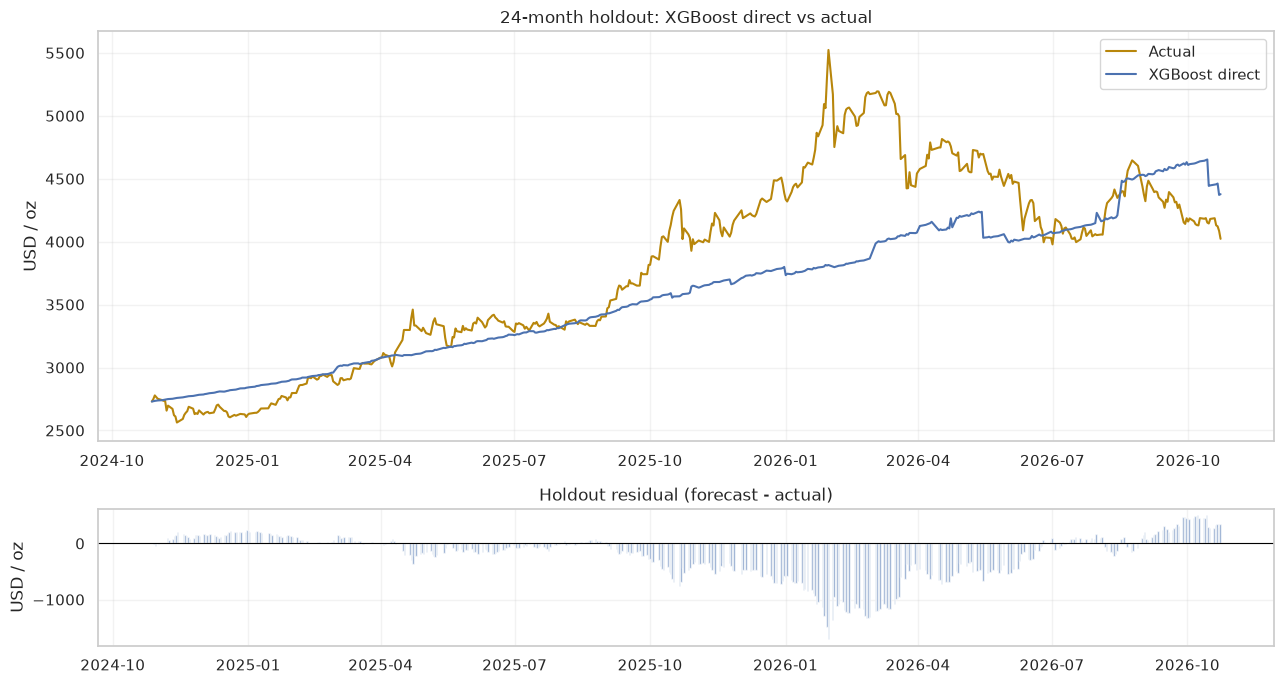

,horizon,MAPE,RMSE,MAE
0,1-5,0.673736,24.242517,18.637080
1,6-21,3.690536,112.784291,97.034654
2,22-63,6.460604,174.477509,171.159900
3,64-126,2.135218,83.581567,62.452634
4,127-252,3.669738,167.078489,129.881466
5,253+,10.821233,614.145812,499.054046


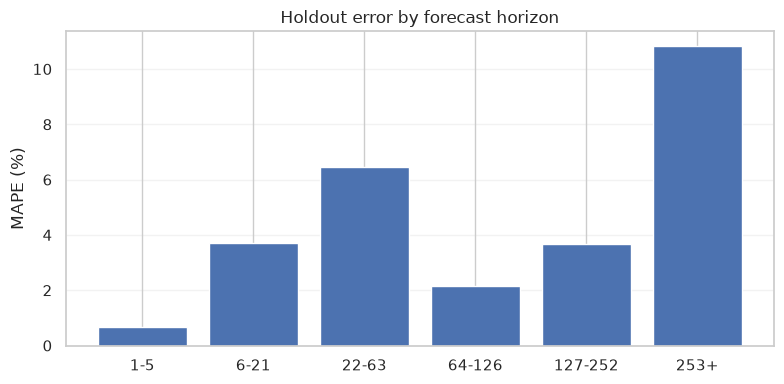

In [10]:
holdout_result = eval_direct(SELECTED_FEATURES, pd.Timestamp("2024-10-26"), 24, 530, PARAMS, stride=3)
holdout_metrics = holdout_result["metrics"]
holdout_df = holdout_result["test"].copy()
holdout_model = holdout_result["model"]

wf_rows = []
for cutoff in WF_CUTS:
    result = eval_direct(SELECTED_FEATURES, cutoff, 12, 270, PARAMS, stride=3)
    wf_rows.append({
        "validation_start": cutoff,
        "validation_end": result["test"]["ds"].max(),
        "train_n": result["train_n"],
        "test_n": result["test_n"],
        **result["metrics"],
        "origin": result["origin_date"],
    })
wf_table = pd.DataFrame(wf_rows)
wf_mean = wf_table[["MAPE", "RMSE", "MAE"]].mean()

print("Direct XGBoost holdout")
print({key: round(value, 3) if isinstance(value, float) else value for key, value in holdout_metrics.items()})
print("\nDirect XGBoost walk-forward")
display(wf_table)
print("Walk-forward mean")
print(wf_mean.round(3).to_string())

holdout_df.to_csv(OUT / "xgb_holdout_predictions.csv", index=False)
wf_table.to_csv(OUT / "xgb_walk_forward_metrics.csv", index=False)

holdout_df["year"] = holdout_df["ds"].dt.year
holdout_year = pd.DataFrame([
    {"year": int(year), **error_metrics(group["actual"], group["pred"])}
    for year, group in holdout_df.groupby("year")
])
holdout_year.to_csv(OUT / "xgb_holdout_by_year.csv", index=False)
display(holdout_year)

fig, axes = plt.subplots(2, 1, figsize=(13, 7), height_ratios=[3, 1])
axes[0].plot(holdout_df["ds"], holdout_df["actual"], color="#b8860b", lw=1.5, label="Actual")
axes[0].plot(holdout_df["ds"], holdout_df["pred"], color="#4c72b0", lw=1.5, label="XGBoost direct")
axes[0].set_title("24-month holdout: XGBoost direct vs actual")
axes[0].set_ylabel("USD / oz")
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[1].bar(holdout_df["ds"], holdout_df["pred"] - holdout_df["actual"], width=1.0, color="#4c72b0", alpha=0.7)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title("Holdout residual (forecast - actual)")
axes[1].set_ylabel("USD / oz")
axes[1].grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "xgb_holdout.png", dpi=150, bbox_inches="tight")
plt.show()

horizon_bins = pd.cut(
    holdout_df["h"], [0, 5, 21, 63, 126, 252, 600],
    labels=["1-5", "6-21", "22-63", "64-126", "127-252", "253+"],
)
horizon_rows = []
for label, group in holdout_df.groupby(horizon_bins, observed=True):
    horizon_rows.append({"horizon": str(label), **error_metrics(group["actual"], group["pred"])})
horizon_table = pd.DataFrame(horizon_rows)
display(horizon_table)
horizon_table.to_csv(OUT / "xgb_holdout_by_horizon.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(horizon_table["horizon"], horizon_table["MAPE"], color="#4c72b0")
ax.set_ylabel("MAPE (%)")
ax.set_title("Holdout error by forecast horizon")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "xgb_horizon_error.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 9 — Recursive one-step diagnostic

The recursive model predicts one business day ahead, appends the prediction to the price path, recomputes gold technical features, and repeats. It uses the same capped-drift target transformation and the same future macro paths. This quantifies how much error compounds outside the direct model.

In [11]:
def build_recursive_dataset(feature_names, cutoff, stride=1):
    origins = np.where(obs.to_numpy())[0]
    origins = origins[origins + 1 < len(bdays)]
    origins = origins[bdays[origins] < cutoff]
    next_positions = origins + 1
    gold = target.to_numpy(dtype=float)
    valid = np.isfinite(gold[next_positions]) & np.isfinite(gold[origins])
    origins = origins[valid]
    next_positions = next_positions[valid]
    if stride > 1 and len(origins) > 0:
        selected = origins[::stride]
        if selected[-1] != origins[-1]:
            selected = np.append(selected, origins[-1])
        origins = selected
        next_positions = origins + 1

    dynamic = [c for c in feature_names if c in FUTURE_CORE or c in TARGET_CAL]
    static = [c for c in feature_names if c not in dynamic]
    X0 = F_hist[static].to_numpy(dtype=np.float32)
    D0 = DYN_HIST[dynamic].to_numpy(dtype=np.float32)
    horizon_col = np.ones((len(origins), 1), dtype=np.float32)
    X = np.column_stack([horizon_col, X0[origins], D0[next_positions]])
    frame = pd.DataFrame(X, columns=["horizon"] + static + dynamic)
    frame["origin_ds"] = bdays[origins]
    frame["target_ds"] = bdays[next_positions]
    frame["h"] = 1
    frame["y"] = (
        np.log(gold[next_positions] / gold[origins])
        - DRIFT.to_numpy(dtype=float)[origins]
    )
    return frame


def predict_recursive(model, feature_names, origin_date, target_dates, final=False):
    static, dynamic = split_feature_names(feature_names)
    origin_date = pd.Timestamp(origin_date)
    target_dates = pd.DatetimeIndex(target_dates)
    gold_path = target.reindex(target.index.union(target_dates)).ffill()
    current_price = float(target.loc[origin_date])
    previous = origin_date
    output = []

    for target_date in target_dates:
        features = build_features(gold_path, ext_all).join(origin_calendar(gold_path.index))
        static_row = features.loc[[previous], static].to_numpy(dtype=np.float32)
        dynamic_source = DYN_FUT if final else DYN_HIST
        dynamic_row = dynamic_source.loc[[target_date], dynamic].to_numpy(dtype=np.float32)
        X = np.column_stack([np.ones((1, 1), dtype=np.float32), static_row, dynamic_row])
        residual = float(model.predict(X)[0])
        drift_series = (np.log(gold_path.ffill()).diff(252) / 252.0).clip(-DRIFT_CAP, DRIFT_CAP)
        drift = float(drift_series.loc[target_date]) if pd.notna(drift_series.loc[target_date]) else 0.0
        current_price = current_price * np.exp(residual + drift)
        gold_path.loc[target_date] = current_price
        output.append({
            "ds": target_date,
            "pred": current_price,
            "pred_logret": residual + drift,
            "h": len(output) + 1,
        })
        previous = target_date
    return pd.DataFrame(output)


def eval_recursive(feature_names, cutoff, months, params, stride=1):
    train = build_recursive_dataset(feature_names, cutoff, stride=stride)
    static, dynamic = split_feature_names(feature_names)
    columns = ["horizon"] + static + dynamic
    model = XGBRegressor(**params)
    model.fit(train[columns], train["y"])
    origin_date = target.loc[target.index < cutoff].dropna().index.max()
    end_date = cutoff + pd.DateOffset(months=months)
    test = target[(target.index >= cutoff) & (target.index < end_date)].dropna()
    target_dates = pd.bdate_range(origin_date + pd.Timedelta(days=1), test.index.max())
    predicted = predict_recursive(model, feature_names, origin_date, target_dates, final=False)
    test_frame = pd.DataFrame({"ds": test.index, "actual": test.values}).merge(predicted, on="ds", how="left")
    return {
        "metrics": error_metrics(test_frame["actual"], test_frame["pred"]),
        "test": test_frame,
        "train_n": len(train),
        "test_n": len(test_frame),
        "origin_date": origin_date,
    }


recursive_holdout = eval_recursive(SELECTED_FEATURES, pd.Timestamp("2024-10-26"), 24, PARAMS)
recursive_wf_rows = []
for cutoff in WF_CUTS:
    result = eval_recursive(SELECTED_FEATURES, cutoff, 12, PARAMS)
    recursive_wf_rows.append({
        "validation_start": cutoff,
        "validation_end": result["test"]["ds"].max(),
        "train_n": result["train_n"],
        "test_n": result["test_n"],
        **result["metrics"],
        "origin": result["origin_date"],
    })
recursive_wf = pd.DataFrame(recursive_wf_rows)
recursive_wf_mean = recursive_wf[["MAPE", "RMSE", "MAE"]].mean()

print("Recursive holdout")
print({key: round(value, 3) if isinstance(value, float) else value for key, value in recursive_holdout["metrics"].items()})
print("\nRecursive walk-forward")
display(recursive_wf)
print("Recursive walk-forward mean")
print(recursive_wf_mean.round(3).to_string())
recursive_holdout["test"].to_csv(OUT / "xgb_recursive_holdout_predictions.csv", index=False)
recursive_wf.to_csv(OUT / "xgb_recursive_walk_forward_metrics.csv", index=False)

Recursive holdout
{'MAPE': 10.72, 'RMSE': 626.746, 'MAE': 457.072}

Recursive walk-forward


,validation_start,validation_end,train_n,test_n,MAPE,RMSE,MAE,origin
0,2022-10-26,2023-10-24,1538,230,12.030139,246.634640,231.071684,2022-10-25
1,2023-10-26,2024-10-25,1742,224,6.568830,203.608193,158.806193,2023-10-24
2,2024-10-26,2025-10-24,1940,235,6.057494,268.415405,203.389586,2024-10-25
3,2025-10-26,2026-10-23,2153,238,9.270491,499.607821,410.957734,2025-10-24


Recursive walk-forward mean
MAPE      8.482
RMSE    304.567
MAE     251.056


## Step 10 — Interval diagnostics and calibration

Separate XGBoost quantile models estimate the 2.5th, 50th, and 97.5th percentiles of the average daily return. They are retained as a diagnostic, but their holdout coverage is checked before use. Because independent quantile fits can under-cover, the final 95% band uses a lognormal interval scaled by 63-day realised gold volatility (`1.96 * sigma * sqrt(h)`). This keeps the band centred on the direct point forecast and makes the uncertainty assumption explicit.

In [12]:
def fit_quantile_models(feature_names, cutoff, hmax, params, stride):
    train = build_direct_dataset(feature_names, hmax=hmax, cutoff=cutoff, stride=stride)
    static, dynamic = split_feature_names(feature_names)
    columns = ["horizon"] + static + dynamic
    models = {}
    for alpha in (0.025, 0.5, 0.975):
        quantile_params = dict(params)
        quantile_params["objective"] = "reg:quantileerror"
        quantile_params["quantile_alpha"] = alpha
        quantile_params["n_estimators"] = min(int(params["n_estimators"]), 300)
        model = XGBRegressor(**quantile_params)
        model.fit(train[columns], train["y"])
        models[alpha] = model
    return models, train


def interval_predictions(models, feature_names, origin_date, target_dates, future=False):
    pieces = []
    for alpha, model in models.items():
        prediction = predict_direct(model, feature_names, origin_date, target_dates, future=future)
        prediction = prediction[["ds", "pred"]].rename(columns={"pred": f"q{alpha}"})
        pieces.append(prediction)
    frame = pieces[0]
    for piece in pieces[1:]:
        frame = frame.merge(piece, on="ds", how="inner")
    lower = frame[["q0.025", "q0.5", "q0.975"]].min(axis=1)
    upper = frame[["q0.025", "q0.5", "q0.975"]].max(axis=1)
    frame["quantile_lower_95"] = lower
    frame["quantile_upper_95"] = upper
    frame["quantile_median"] = frame["q0.5"]
    return frame


quantile_holdout_models, quantile_holdout_train = fit_quantile_models(
    SELECTED_FEATURES, pd.Timestamp("2024-10-26"), 530, PARAMS, stride=3
)
holdout_origin = holdout_result["origin_date"]
quantile_holdout = interval_predictions(
    quantile_holdout_models, SELECTED_FEATURES, holdout_origin, holdout_df["ds"]
)
coverage_frame = holdout_df.merge(quantile_holdout, on="ds", how="left")
quantile_coverage = float(
    ((coverage_frame["actual"] >= coverage_frame["quantile_lower_95"])
     & (coverage_frame["actual"] <= coverage_frame["quantile_upper_95"])).mean() * 100
)
quantile_width = float(
    ((coverage_frame["quantile_upper_95"] - coverage_frame["quantile_lower_95"])
     / coverage_frame["actual"]).mean() * 100
)

realized_vol = np.log(target.dropna()).diff().rolling(63).std()
holdout_vol = float(realized_vol.loc[holdout_origin])
coverage_frame["sigma_h"] = holdout_vol * np.sqrt(coverage_frame["h"].astype(float))
coverage_frame["lower_95"] = coverage_frame["pred"] * np.exp(-1.96 * coverage_frame["sigma_h"])
coverage_frame["upper_95"] = coverage_frame["pred"] * np.exp(1.96 * coverage_frame["sigma_h"])
coverage = float(
    ((coverage_frame["actual"] >= coverage_frame["lower_95"])
     & (coverage_frame["actual"] <= coverage_frame["upper_95"])).mean() * 100
)
interval_width = float(
    ((coverage_frame["upper_95"] - coverage_frame["lower_95"]) / coverage_frame["actual"]).mean() * 100
)
coverage_table = pd.DataFrame([
    {"metric": "holdout 95% volatility-band coverage (%)", "value": coverage},
    {"metric": "mean volatility-band width (% of price)", "value": interval_width},
    {"metric": "holdout 95% quantile-model coverage (%)", "value": quantile_coverage},
    {"metric": "mean quantile-model width (% of price)", "value": quantile_width},
    {"metric": "holdout-origin 63-day volatility (% daily)", "value": holdout_vol * 100},
])
display(coverage_table)
coverage_table.to_csv(OUT / "xgb_interval_coverage.csv", index=False)
coverage_frame.to_csv(OUT / "xgb_holdout_interval_predictions.csv", index=False)

quantile_final_models, quantile_final_train = fit_quantile_models(
    SELECTED_FEATURES, None, HORIZON, PARAMS, stride=1
)
quantile_future = interval_predictions(
    quantile_final_models, SELECTED_FEATURES, last_observed, future_regs.index, future=True
)
final_vol = float(realized_vol.loc[last_observed])

,metric,value
0,holdout 95% volatility-band coverage (%),99.365751
1,mean volatility-band width (% of price),52.895411
2,holdout 95% quantile-model coverage (%),52.431290
3,mean quantile-model width (% of price),21.775175
4,holdout-origin 63-day volatility (% daily),0.914853


## Step 11 — Final six-month forecast

The final direct model is refitted on all observed origins with a 126-business-day horizon. The point forecast is the mean model; the band is the calibrated 63-day realised-volatility interval.

,horizon,date,forecast_usd,lower_95,upper_95,change_from_last_pct
0,1 business day,2026-10-27,4018.138936,3920.106520,4118.622907,0.058243
1,1 month,2026-11-24,4087.225951,3649.816125,4577.056872,1.778623
2,3 months,2027-01-21,4205.858343,3457.093088,5116.797250,4.732764
3,6 months,2027-04-20,4411.308992,3343.153299,5820.746250,9.848822


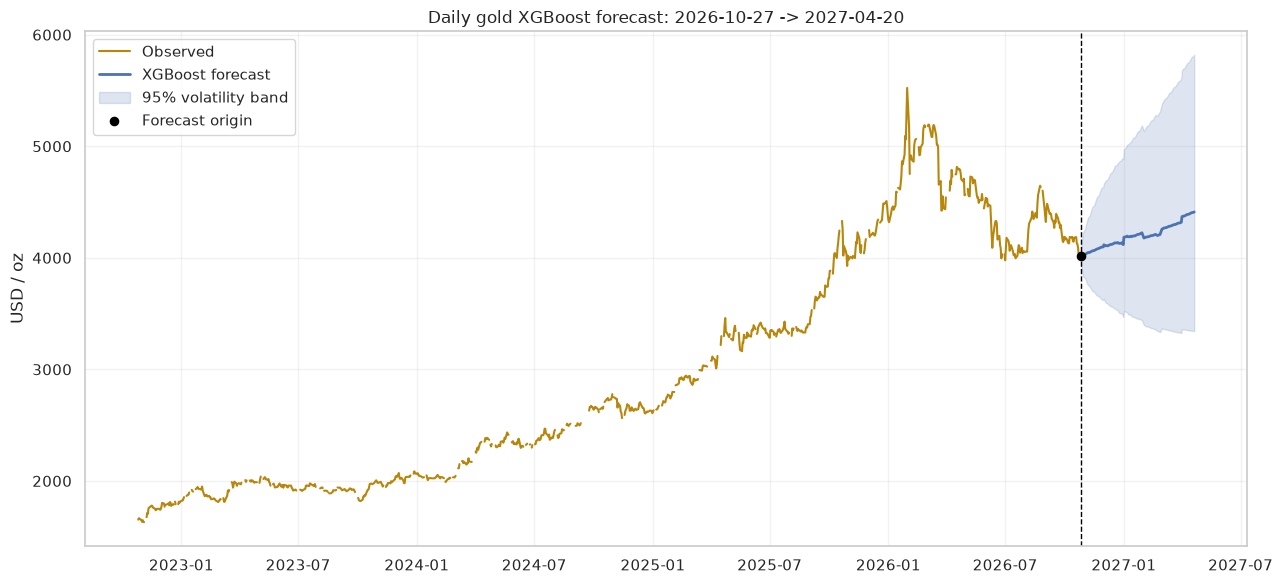

In [13]:
final_model, final_train, final_columns = fit_direct_model(
    SELECTED_FEATURES, None, HORIZON, PARAMS, stride=1
)
final_prediction = predict_direct(
    final_model, SELECTED_FEATURES, last_observed, future_regs.index, future=True
)
forecast = final_prediction.merge(quantile_future, on="ds", how="left")
forecast["yhat"] = forecast["pred"]
forecast["sigma_h"] = final_vol * np.sqrt(forecast["h"].astype(float))
forecast["lower_95"] = forecast["yhat"] * np.exp(-1.96 * forecast["sigma_h"])
forecast["upper_95"] = forecast["yhat"] * np.exp(1.96 * forecast["sigma_h"])
forecast["change_from_last_pct"] = (forecast["yhat"] / last_price - 1) * 100

summary_rows = []
for label, position in [("1 business day", 0), ("1 month", 20), ("3 months", 62), ("6 months", -1)]:
    row = forecast.iloc[position]
    summary_rows.append({
        "horizon": label,
        "date": row["ds"],
        "forecast_usd": row["yhat"],
        "lower_95": row["lower_95"],
        "upper_95": row["upper_95"],
        "change_from_last_pct": row["change_from_last_pct"],
    })
forecast_summary = pd.DataFrame(summary_rows)
display(forecast_summary)
forecast_summary.to_csv(OUT / "xgb_forecast_summary.csv", index=False)
forecast.to_csv(OUT / "xgb_forecast_daily.csv", index=False)

history_plot = panel.loc[panel.index >= panel.index.max() - pd.DateOffset(years=4)]
fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(history_plot.index, history_plot["gold"], color="#b8860b", lw=1.5, label="Observed")
ax.plot(forecast["ds"], forecast["yhat"], color="#4c72b0", lw=2, label="XGBoost forecast")
ax.fill_between(
    forecast["ds"], forecast["lower_95"], forecast["upper_95"],
    color="#4c72b0", alpha=0.18, label="95% volatility band",
)
ax.axvline(last_observed, color="black", ls="--", lw=1)
ax.scatter([last_observed], [last_price], color="black", zorder=5, s=35, label="Forecast origin")
ax.set_title("Daily gold XGBoost forecast: 2026-10-27 -> 2027-04-20")
ax.set_ylabel("USD / oz")
ax.legend(loc="upper left")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "xgb_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 12 — Feature importance and model summary

Gain importance is shown for the final direct model. Correlated macro features can share or hide importance, so the grouped picture matters more than a single rank.

,feature,gain
0,gold_skew_63,0.110398
1,fed_funds_level,0.069277
2,gold_ret_252,0.045338
3,dxy_level,0.039147
4,ust10y_chg_63,0.036562
5,real_yield_level,0.029605
6,cpi_yoy_z252,0.029482
7,gold_ma_dist_200,0.028503
8,month_cos,0.028082
9,gold_rsi_14,0.027485


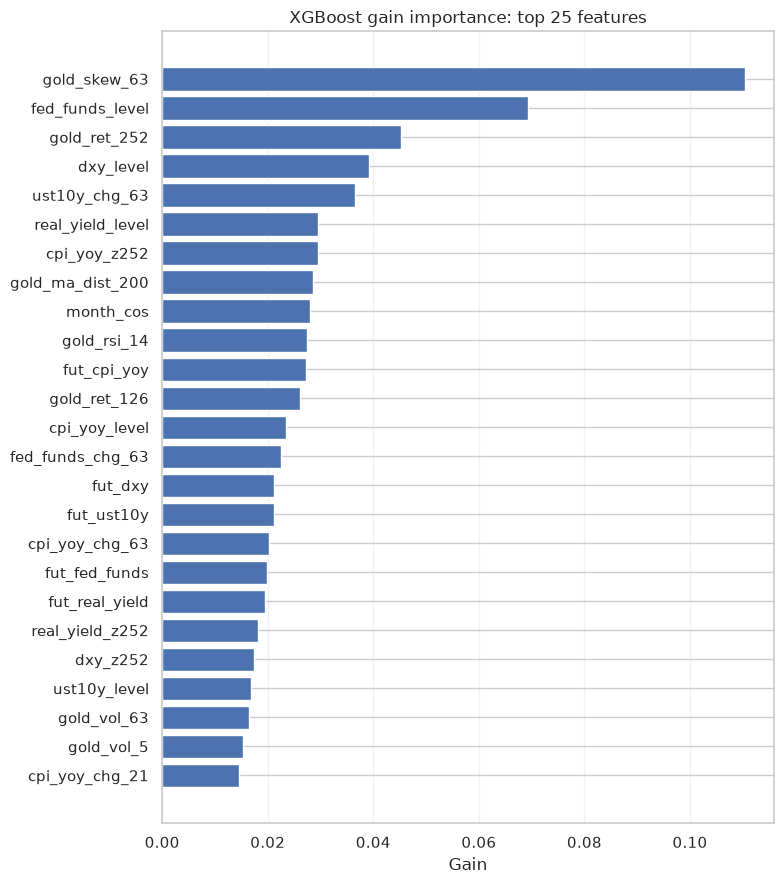

,model,evaluation,MAPE,RMSE,MAE
0,Prophet selected 4-regressor,24m holdout,6.351629,420.087722,276.838774
1,Prophet selected 4-regressor,12m walk-forward mean,5.990417,242.700167,197.490863
2,XGBoost direct,24m holdout,7.398349,453.786464,314.737758
3,XGBoost direct,12m walk-forward mean,11.197884,409.370169,328.055921
4,XGBoost recursive,24m holdout,10.719608,626.745803,457.072055
5,XGBoost recursive,12m walk-forward mean,8.481738,304.566515,251.056299
6,Random walk,24m holdout,26.047770,1314.371389,1098.396047
7,Random walk,12m walk-forward mean,11.451526,424.658757,340.305027


Saved files:
  xgb_feature_importance.csv
  xgb_feature_importance.png
  xgb_feature_list.json
  xgb_feature_set_comparison.csv
  xgb_forecast.png
  xgb_forecast_daily.csv
  xgb_forecast_summary.csv
  xgb_holdout.png
  xgb_holdout_by_horizon.csv
  xgb_holdout_by_year.csv
  xgb_holdout_interval_predictions.csv
  xgb_holdout_predictions.csv
  xgb_horizon_error.png
  xgb_interval_coverage.csv
  xgb_model_comparison.csv
  xgb_model_summary.json
  xgb_parameter_sensitivity.csv
  xgb_recursive_holdout_predictions.csv
  xgb_recursive_walk_forward_metrics.csv
  xgb_walk_forward_metrics.csv


In [14]:
importance = pd.DataFrame({
    "feature": final_model.feature_names_in_,
    "gain": final_model.feature_importances_,
}).sort_values("gain", ascending=False).reset_index(drop=True)
importance.to_csv(OUT / "xgb_feature_importance.csv", index=False)
display(importance.head(25))

fig, ax = plt.subplots(figsize=(8, 9))
top = importance.head(25).sort_values("gain")
ax.barh(top["feature"], top["gain"], color="#4c72b0")
ax.set_title("XGBoost gain importance: top 25 features")
ax.set_xlabel("Gain")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "xgb_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

comparison_rows = [
    {"model": "Prophet selected 4-regressor", "evaluation": "24m holdout",
     "MAPE": prophet_holdout_row["MAPE_anchored"], "RMSE": prophet_holdout_row["RMSE_anchored"],
     "MAE": prophet_holdout_row["MAE_anchored"]},
    {"model": "Prophet selected 4-regressor", "evaluation": "12m walk-forward mean",
     "MAPE": prophet_wf_mean["MAPE_anchored"], "RMSE": prophet_wf_mean["RMSE_anchored"],
     "MAE": prophet_wf_mean["MAE_anchored"]},
    {"model": "XGBoost direct", "evaluation": "24m holdout", **holdout_metrics},
    {"model": "XGBoost direct", "evaluation": "12m walk-forward mean", **wf_mean.to_dict()},
    {"model": "XGBoost recursive", "evaluation": "24m holdout", **recursive_holdout["metrics"]},
    {"model": "XGBoost recursive", "evaluation": "12m walk-forward mean", **recursive_wf_mean.to_dict()},
    {"model": "Random walk", "evaluation": "24m holdout", **rw_holdout},
    {"model": "Random walk", "evaluation": "12m walk-forward mean", **rw_wf_mean.to_dict()},
]
comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table)
comparison_table.to_csv(OUT / "xgb_model_comparison.csv", index=False)

metadata = {
    "selected_feature_set": SELECTED_SET,
    "n_features": len(SELECTED_FEATURES),
    "drift_cap_daily_log": DRIFT_CAP,
    "holdout_metrics": holdout_metrics,
    "walk_forward_mean": wf_mean.to_dict(),
    "recursive_holdout": recursive_holdout["metrics"],
    "recursive_walk_forward_mean": recursive_wf_mean.to_dict(),
    "interval_method": "63-day realised volatility, lognormal 1.96 sigma",
    "interval_coverage_pct": coverage,
    "quantile_interval_coverage_pct": quantile_coverage,
    "holdout_origin_vol_63d_daily": holdout_vol,
    "forecast_origin_vol_63d_daily": final_vol,
    "forecast_origin": str(last_observed.date()),
    "forecast_origin_price": last_price,
    "forecast_end": str(forecast["ds"].max().date()),
}
with open(OUT / "xgb_model_summary.json", "w") as handle:
    json.dump(metadata, handle, indent=2, default=str)

with open(OUT / "xgb_feature_list.json", "w") as handle:
    json.dump({
        "selected_feature_set": SELECTED_SET,
        "features": SELECTED_FEATURES,
        "feature_sets": {name: features for name, features in FSETS.items()},
    }, handle, indent=2)

print("Saved files:")
for path in sorted(OUT.glob("*")):
    print(f"  {path.name}")

## Summary and limitations

**What this notebook does**

- Reuses the cleaned daily target and release-lag-aligned external panel from the Prophet notebook.
- Engineers gold technical, macro, market-risk, calendar, and known-future-macro features without target leakage.
- Models average daily log returns with a capped 252-day trend bridge, avoiding raw-price extrapolation.
- Evaluates a direct multi-horizon XGBoost model on the same 24-month holdout and four 12-month walk-forward folds as Prophet.
- Includes a recursive one-step diagnostic and separate Brent/WTI oil ablations.
- Reports quantile-model diagnostics and a calibrated 63-day volatility band; both holdout coverages are documented.

**Key limitation**

XGBoost is a tree ensemble: it cannot extrapolate a price trend beyond the feature values and return leaves seen in training. The 2025-2026 gold regime, including the January 2026 spike and subsequent drawdown, is therefore a hard stress test. The direct model is compared honestly against Prophet rather than tuned on the outer holdout.